# Part 1 ConvNet for small dataset

Having to train an image classification model using very little data is a common situation, which you’ll likely encounter in practice if you ever do computer vision in a professional context. A “few” samples can mean anywhere from a few hundred to a few tens of thousands of images. As a practical example, we’ll focus on classifying images as dogs or cats, in a dataset containing 4,000 pictures of cats and dogs (2,000 cats, 2,000 dogs). We’ll use 2,000 pictures for training – 1,000 for validation, and 1,000 for testing.

# Dataset


This original dataset contains 25,000 images of dogs and cats (12,500 from each class) and is ~800MB large (compressed). However, to simulate the real case of having a limited numeber of images we will only use 4,000.


You can download the whole dataset from Kaggle: https://www.kaggle.com/c/dogs-vs-cats/data or a subset of 4,000 from my Google Drive
https://drive.google.com/file/d/18PsGch7egeczC4zLjYw3dXGjHyL-Kebw/view?usp=sharing

However, if you are using Google Colab and don't want to download the whole dataset on your computer, you can load them directly into a temporary Colab memory using commands below. It will save you time and memory, but you will have to run this every time.



```
! gdown --id 18PsGch7egeczC4zLjYw3dXGjHyL-Kebw
! unzip /content/dataset_cats_dogs.zip
```

After downloading the data, you have to arrange them correctly in the catalogues. Data should be split into separate catalogs for dogs and for cats. You can do it manually or in python (for example using os and shutil libraries).

```
main_directory/
...train/
......class_a/
.........a_image_1.jpg
.........a_image_2.jpg
......class_b/
.........b_image_1.jpg
.........b_image_2.jpg
...validation/
......class_a/
.........a_image_1.jpg
.........a_image_2.jpg
......class_b/
.........b_image_1.jpg
.........b_image_2.jpg
```


Please check the train/validation/test datasets. We now have 2000 training images, then 1000 validation images and 1000 test images (optional). In each split, there is the same number of samples from each class: this is a balanced binary classification problem, which means that classification accuracy will be an appropriate measure of success.

# Network architecture

You've already built a small convnet for MNIST in the previous exercise. You will reuse the same general structure: our convnet will be a stack of alternated Conv2D (with relu activation) and MaxPooling2D layers.

However, since we are dealing with bigger images and a more complex problem, we will make our network larger: it will have one more Conv2D + MaxPooling2D stage. Here, since we start from inputs of size 150×150 (a somewhat arbitrary choice), we end up with feature maps of size 7×7 right before the Flatten layer. Note that the depth of the feature maps is progressively increasing in the network (from 32 to 128), while the size of the feature maps is decreasing (from 148×148 to 7×7). This is a pattern that you will see in almost all convnets. Since we are attacking a binary classification problem, we are ending the network with a single unit (a Dense layer of size 1) and a sigmoid activation. This unit will encode the probability that the network is looking at one class or the other.

Please create your network architecture based on the information above (4x Conv2d, 4x Maxpooling layers and then Flatten, 2 x Dense layer).

In [1]:
import keras
from keras import layers, models

model = keras.Sequential([
    layers.Input(shape=(150, 150, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

model.summary()

I0000 00:00:1792622796.287499  180719 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792622798.110208  180719 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3994 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2060, pci bus id: 0000:07:00.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,453,121 (13.17 MB)

 Trainable params: 3,453,121 (13.17 MB)

 Non-trainable params: 0 (0.00 B)



```

Layer (type)                 Output Shape              Param #   
=================================================================
rescaling_1 (Rescaling)     (None, 150, 150, 3)       0         
_________________________________________________________________
conv2d_1 (Conv2D)            (None, 148, 148, 32)      896       
_________________________________________________________________
max_pooling2d_1 (MaxPooling2 (None, 74, 74, 32)        0         
_________________________________________________________________
conv2d_2 (Conv2D)            (None, 72, 72, 64)        18496     
_________________________________________________________________
max_pooling2d_2 (MaxPooling2 (None, 36, 36, 64)        0         
_________________________________________________________________
conv2d_3 (Conv2D)            (None, 34, 34, 128)       73856     
_________________________________________________________________
max_pooling2d_3 (MaxPooling2 (None, 17, 17, 128)       0         
_________________________________________________________________
conv2d_4 (Conv2D)            (None, 15, 15, 128)       147584    
_________________________________________________________________
max_pooling2d_4 (MaxPooling2 (None, 7, 7, 128)         0         
_________________________________________________________________
flatten_1 (Flatten)          (None, 6272)              0         
_________________________________________________________________
dense_1 (Dense)              (None, 512)               3211776   
_________________________________________________________________
dense_2 (Dense)              (None, 1)                 513       
=================================================================
Total params: 3,453,121
Trainable params: 3,453,121
Non-trainable params: 0
__________________________

```



Compilation step:

* RMSprop optimizer - with learning rate parameter(lr=1e-4)
* Binary crossentropy loss funtion
* Accuracy metric


In [2]:
model.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,453,121 (13.17 MB)

 Trainable params: 3,453,121 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

# Data preprocessing

Data preprocessing steps include the following:

* Read the picture files.
* Decode the JPEG content to RBG grids of pixels.
* Convert these into floating-point tensors.
* Rescale the pixel values (between 0 and 255) to the [0, 1] interval (as you know, neural networks prefer to deal with small input values).

It may seem a bit daunting, but thankfully Keras has utilities to take care of these steps automatically. It has a module with image processing helper tools, located at `tensorflow.keras.preprocessing`. A function called `image_dataset_from_directory` allows to automatically turn image files on disk into batches of pre-processed tensors. One of the useful properties is the ability to automatically label data based on which folder they are in. That is why, at the beginning of the exercise, we put dogs and cats into the appropriate folders.

*Trivia: In older versions of the library we used to work with `ImageDataGenerator` Class to load images. You may still find it in many tutorials. It is a very nice tool with many additional features (such as data augmentation), but you will need older tensorflow and keras version for that.*

In [3]:
import keras
from keras import layers, models
from tensorflow.keras.preprocessing import image_dataset_from_directory

train_dataset = image_dataset_from_directory(
    "dataset/train",  # This is the target directory
    labels="inferred",
    label_mode="binary", # Since we use binary_crossentropy loss, we need binary labels
    class_names=None,
    color_mode="rgb",
    batch_size=20,
    image_size=(150,150), # All images have different sizes and will be resized to 150x150
    shuffle=True,
)

val_dataset = image_dataset_from_directory(
    "dataset/val",
    labels="inferred",
    label_mode="binary",
    class_names=train_dataset.class_names,
    color_mode="rgb",
    batch_size=20,
    image_size=(150, 150),
    shuffle=False,
)

test_dataset = image_dataset_from_directory(
    "dataset/test",
    labels="inferred",
    label_mode="binary",
    class_names=train_dataset.class_names,
    color_mode="rgb",
    batch_size=20,
    image_size=(150, 150),
    shuffle=False,
)


early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=100,
    restore_best_weights=True,
)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.


In [4]:
history = model.fit(train_dataset, epochs=30, validation_data=val_dataset, callbacks=[early_stop])

/home/user/Documents/programming/python/PracticalAspectsOfDeepLearningCourse/lab3/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/30


I0000 00:00:1792622801.518464  180719 service.cc:154] XLA service 0x49b3d5d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792622801.518487  180719 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 2060, Compute Capability 7.5 (Driver: 13.2.0[595.99.2]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1792622801.546316  180719 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792622802.012326  180719 cuda_dnn.cc:442] Loaded cuDNN version 92700
W0000 00:00:1792622803.561415  180941 cuda_timer.cc:88] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


 11/100 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.5182 - loss: 0.6928

I0000 00:00:1792622804.274064  180719 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.5325 - loss: 0.6908 - val_accuracy: 0.5340 - val_loss: 0.6803
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.5820 - loss: 0.6724 - val_accuracy: 0.6020 - val_loss: 0.6558
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.6255 - loss: 0.6447 - val_accuracy: 0.5690 - val_loss: 0.6811
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.6590 - loss: 0.6147 - val_accuracy: 0.6490 - val_loss: 0.6153
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.6965 - loss: 0.5812 - val_accuracy: 0.6650 - val_loss: 0.6058
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.7050 - loss: 0.5668 - val_accuracy: 0.6830 - val_loss: 0.5861
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.7300 - loss: 0.5460 - val_accuracy: 0.6710 - val_loss: 0.5918
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.7480 - loss: 0.5231 - val_accuracy: 0.674

# Outcome analysis

 Plot the loss and accuracy of the model over the training and validation data during training.

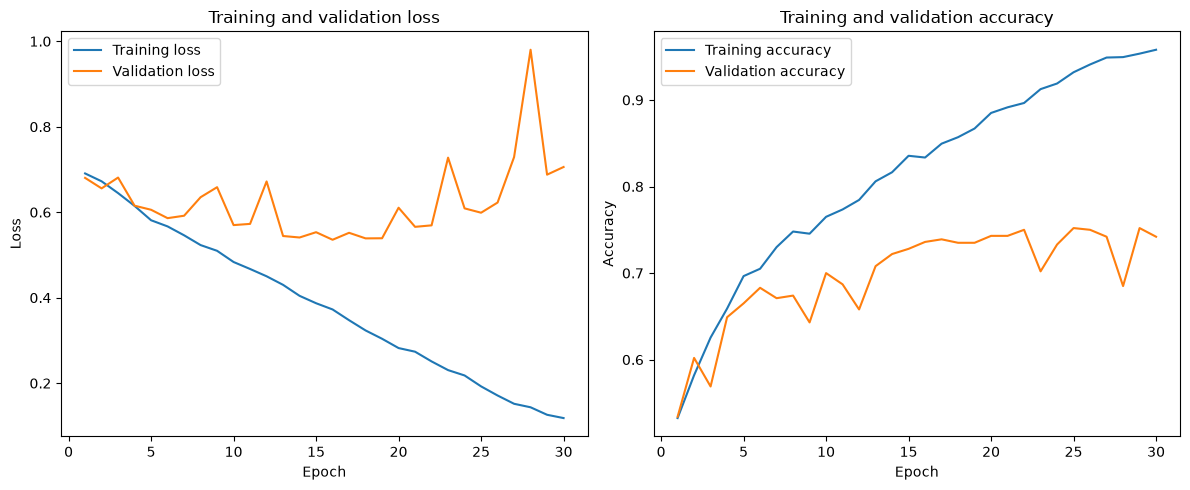

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7410 - loss: 0.5486
Test loss: 0.549
Test accuracy: 0.741


In [5]:
import matplotlib.pyplot as plt

epochs = range(1, len(history.history["loss"]) + 1)

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 5))

ax_loss.plot(epochs, history.history["loss"], label="Training loss")
ax_loss.plot(epochs, history.history["val_loss"], label="Validation loss")
ax_loss.set_title("Training and validation loss")
ax_loss.set_xlabel("Epoch")
ax_loss.set_ylabel("Loss")
ax_loss.legend()

ax_acc.plot(epochs, history.history["accuracy"], label="Training accuracy")
ax_acc.plot(epochs, history.history["val_accuracy"], label="Validation accuracy")
ax_acc.set_title("Training and validation accuracy")
ax_acc.set_xlabel("Epoch")
ax_acc.set_ylabel("Accuracy")
ax_acc.legend()

plt.tight_layout()
plt.show()

test_loss, test_accuracy = model.evaluate(test_dataset)
print(f"Test loss: {test_loss:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")

 In these plots, you should see that the model is overfitting. Our training accuracy increases linearly over time, until it reaches nearly 100%, while our validation accuracy stalls at 70-72%. Our validation loss reaches its minimum after only five epochs then stalls, while the training loss keeps decreasing linearly until it reaches nearly 0.

Because we only have relatively few training samples (2000), overfitting is going to be our number one concern. There are many techniques that can help mitigate overfitting, such as reducing the number of epochs, adding dropout layers dropout, or weight decay (L2 regularization). We will look at them in the next task.

# Part 2 Data augmentation

Data augmentation takes the approach of generating more training data from existing training samples, by “augmenting” the samples via a number of random transformations that yield believable-looking images. The common-sense approach would be the manual creation of more images and applying small changes. However, it can be done easier and more efficiently in Keras.

The goal is that at training time, our model would never see the exact same picture twice. It will change each image at the loading stage. This helps the model get exposed to more aspects of the data and generalize better. Below you can see an example.

In [6]:
baseline_history = history

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
])

model_aug = keras.Sequential([
    layers.Input(shape=(150, 150, 3)),
    data_augmentation,
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

model_aug.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

aug_history = model_aug.fit(
    train_dataset,
    epochs=100,
    validation_data=val_dataset,
    callbacks=[early_stop]
)

Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.5095 - loss: 0.6946 - val_accuracy: 0.5650 - val_loss: 0.6880
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.5440 - loss: 0.6881 - val_accuracy: 0.5590 - val_loss: 0.6797
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.5635 - loss: 0.6827 - val_accuracy: 0.6080 - val_loss: 0.6651
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.5845 - loss: 0.6712 - val_accuracy: 0.6160 - val_loss: 0.6504
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.6075 - loss: 0.6589 - val_accuracy: 0.5970 - val_loss: 0.6511
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.6190 - loss: 0.6501 - val_accuracy: 0.6360 - val_loss: 0.6344
Epoch 7/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.6480 - loss: 0.6330 - val_accuracy: 0.6450 - val_loss: 0.6241
Epoch 8/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.6415 - loss: 0.6294 - 

If we train a new network using this data augmentation configuration, our network will never see twice the same input. However, the inputs that it sees are still heavily intercorrelated, since they come from a small number of original images, so the results won't be that much better.

Set parameters of the data augmentation yourself. We tested the values of rotations and zooms at about 0,2 but you can experiment with those.


Train the network using data augmentation. Note, that this time we train the network longer (**for about 100 epochs**) and it still increases. If training takes too much time on your machine, you can try lower numbers. After 100 epochs you can expect validation accuracy of about 80-82%, after 30 epochs about 77%. Plot the results of 30 epochs and compare them with those without augmentation.

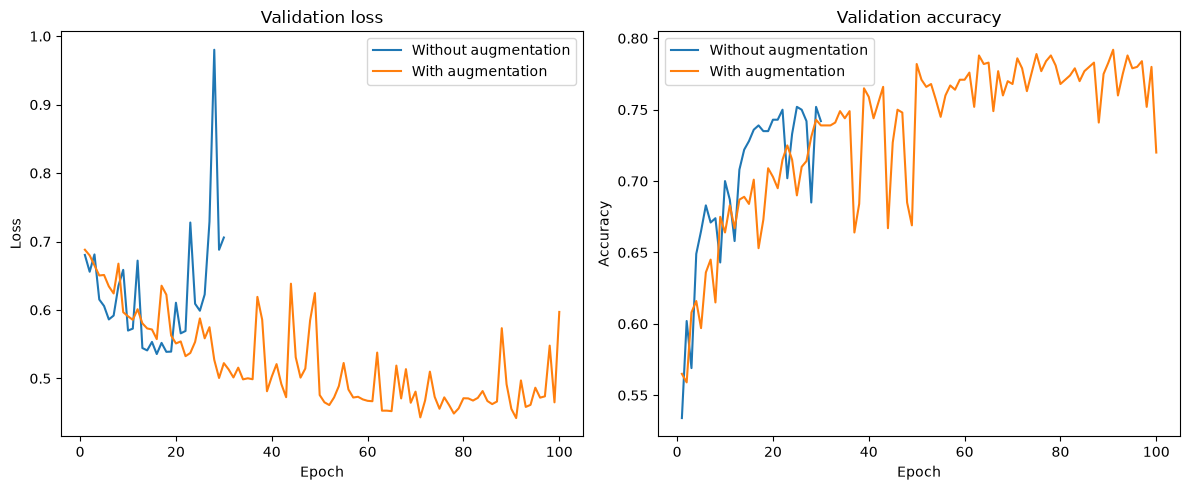

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7820 - loss: 0.4958
Test loss: 0.496
Test accuracy: 0.782


In [7]:
import matplotlib.pyplot as plt

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 5))

for run, label in [
    (baseline_history, "Without augmentation"),
    (aug_history, "With augmentation"),
]:
    epochs = range(1, len(run.history["loss"]) + 1)
    ax_loss.plot(epochs, run.history["val_loss"], label=label)
    ax_acc.plot(epochs, run.history["val_accuracy"], label=label)

ax_loss.set(title="Validation loss", xlabel="Epoch", ylabel="Loss")
ax_acc.set(title="Validation accuracy", xlabel="Epoch", ylabel="Accuracy")
ax_loss.legend()
ax_acc.legend()

plt.tight_layout()
plt.show()

test_loss, test_accuracy = model_aug.evaluate(test_dataset)
print(f"Test loss: {test_loss:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")

# Part 3 Adding Dropout Layer

A dropout layer is a very simple, yet quite counter-intuitive method. What it does is basically cutting off half of the connection between the layers. You may ask yourself a question - Why do I train the network so hard, only to randomly throw half of the information away? Surprisingly, this works. In many situations network is overfitting to the data so much, that randomly cutting 20%, 30%, or even 50% of connection during training phase will force the other neurons to start working.

To further combat overfitting, we will also add a Dropout layer to our Dogs and Cats example. Add the Dropout layer right before the densely-connected classifier.

In [8]:
from tensorflow import keras
from tensorflow.keras import layers

model_dropout = keras.Sequential([
    layers.Input(shape=(150, 150, 3)),
    data_augmentation,
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dropout(0.2),
    layers.Dense(512, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

model_dropout.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

dropout_history = model_dropout.fit(
    train_dataset,
    epochs=100,
    validation_data=val_dataset,
    callbacks=[early_stop]
)


Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.5035 - loss: 0.6935 - val_accuracy: 0.5810 - val_loss: 0.6890
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.5345 - loss: 0.6885 - val_accuracy: 0.5760 - val_loss: 0.6773
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.5695 - loss: 0.6788 - val_accuracy: 0.5910 - val_loss: 0.6679
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.5925 - loss: 0.6666 - val_accuracy: 0.5830 - val_loss: 0.6581
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.6055 - loss: 0.6524 - val_accuracy: 0.5980 - val_loss: 0.6728
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.6360 - loss: 0.6484 - val_accuracy: 0.6280 - val_loss: 0.6372
Epoch 7/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.6485 - loss: 0.6367 - val_accuracy: 0.6100 - val_loss: 0.6617
Epoch 8/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.6565 - loss: 0.6218 - 

 Wy should expect higher accuracy, about 80-82% compared to 77-80% in the previous task. Plot the results and compare them.

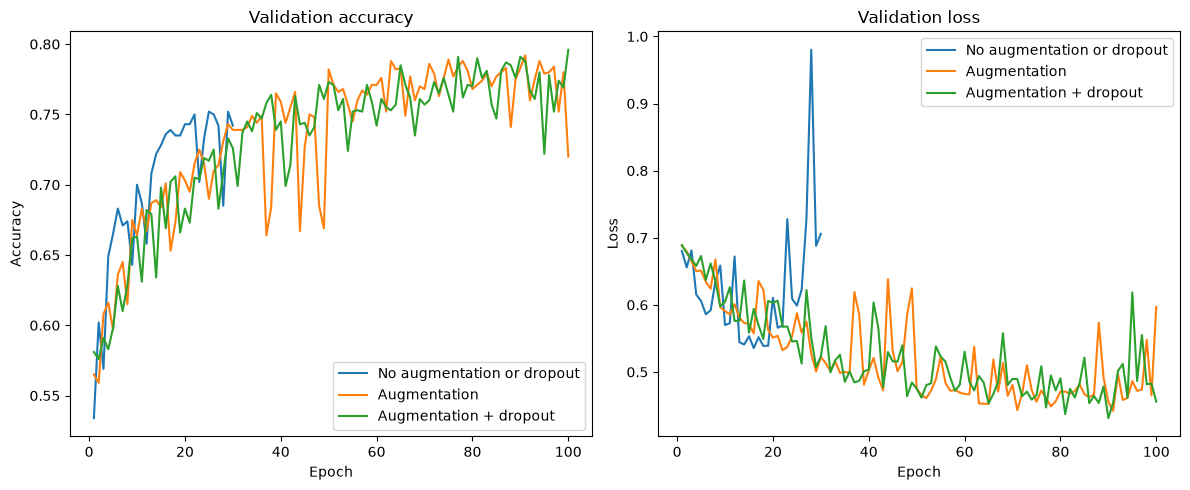

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7790 - loss: 0.4639
Test loss: 0.464
Test accuracy: 0.779


In [9]:
import matplotlib.pyplot as plt

fig, (ax_acc, ax_loss) = plt.subplots(1, 2, figsize=(12, 5))

runs = [
    (baseline_history, "No augmentation or dropout"),
    (aug_history, "Augmentation"),
    (dropout_history, "Augmentation + dropout"),
]

for run, label in runs:
    epochs = range(1, len(run.history["val_accuracy"]) + 1)
    ax_acc.plot(epochs, run.history["val_accuracy"], label=label)
    ax_loss.plot(epochs, run.history["val_loss"], label=label)

ax_acc.set(title="Validation accuracy", xlabel="Epoch", ylabel="Accuracy")
ax_loss.set(title="Validation loss", xlabel="Epoch", ylabel="Loss")
ax_acc.legend()
ax_loss.legend()

plt.tight_layout()
plt.show()

test_loss, test_accuracy = model_dropout.evaluate(test_dataset)
print(f"Test loss: {test_loss:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")

 If you want, you can also try training the model with a dropout layer, but without image augmentation, to see which one is better. Both methods should give better results than training without any of them, but worse than having them combined. Augmentation will improve the model much more than dropout. You may, however, notice, that dropout is faster.

If you want, you can change the dropout parameter. Maybe we cut off too much? You can also try to experiment with putting the dropout layer in different places (maybe between convolutions), or even adding more dropout layers. There is hardly ever one universal way to implement a model. Make some modifications and comment on the results.

# Part 4 Pre-trained Models (Transfer Learning)

A common and highly effective approach to deep learning on small image datasets is to leverage a pre-trained network. A pre-trained network is simply a saved network previously trained on a large dataset. If this original dataset is large enough and general enough, then the spatial feature hierarchy learned by the pre-trained network can effectively act as a generic model of our visual world, and its features can prove useful for many different computer vision problems, even though these new problems might involve completely different classes from those of the original task.

During this exercise we will use the VGG16 architecture, developed by Karen Simonyan and Andrew Zisserman in 2014, a simple and widely used convnet architecture for ImageNet. Some another pre-trained models are VGG, ResNet, Inception, DenseNet, MobileNet, EfficientNet, ConvNeXt.

# Transfer Learning

As we saw previously, convnets used for image classification comprise two parts: they start with a series of pooling and convolution layers, and they end with a densely-connected classifier. The first part is called the “convolutional base” of the model.

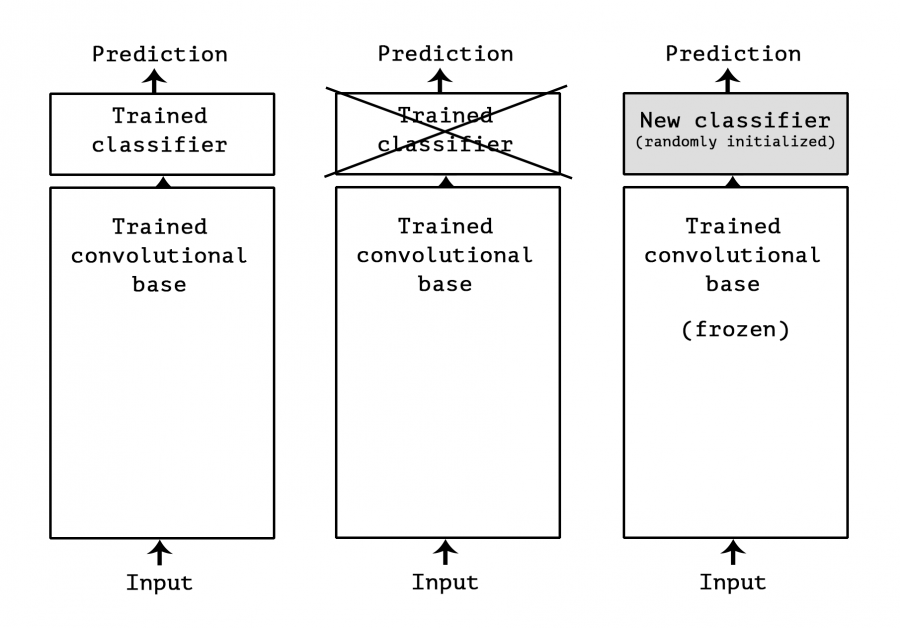

Feature maps of a convnet are maps of generic concepts over a picture. On the other end, the representations learned by the classifier will be very specific to the set of classes that the model was trained on. Additionally, representations found in densely-connected layers no longer contain any information about where objects are located in the input image: these layers get rid of the notion of space.

The VGG16 model, among others, comes pre-packaged with Keras. You can import it from the `keras.applications` module. Here's the list of some image classification models (all pre-trained on the ImageNet dataset) that are available as part of `keras.applications`:

*   VGG16
*   VGG19
*   Xception
*   Inception
*   ResNet
*   DenseNet
*   MobileNet
*   EfficientNet
*   ConvNeXt


# VGG-16 model

Import the model from Keras:

In [10]:
from tensorflow.keras.applications import VGG16

conv_base = VGG16(weights='imagenet',
                  include_top=False,
                  input_shape=(150, 150, 3))


 We passed three arguments to the constructor:

*   weights, to specify which weight checkpoint to initialize the model from
*   include_top, which refers to including or not the densely-connected classifier on top of the network. By default, this densely-connected classifier would correspond to the 1000 classes from ImageNet. Since we intend to use our own densely-connected classifier (with only two classes, cat and dog), we don't need to include it.
*   input_shape, the shape of the image tensors that we will feed to the network. This argument is purely optional: if we don't pass it, then the network will be able to process inputs of any size.


Please analyze the model of VGG-16 (model summary) - after compilation. What is the final feature map shape?

# Pre-trained part as an extended layer

Because models in Keras behave just like layers, you can add a model (like our conv_base) to a Sequential model just like you would add a layer:

In [11]:
from tensorflow.keras import models
from tensorflow.keras import layers

model = models.Sequential()
model.add(conv_base)
model.add(layers.Flatten())
model.add(layers.Dense(256, activation='relu'))
model.add(layers.Dense(1, activation='sigmoid'))

Please analyse the model summary. How many parameters do you have now ? How many parameters are trainable?
Before we compile and train our model, a very important thing to do is to freeze the convolutional base. “Freezing” a layer or set of layers means preventing their weights from getting updated during training. If we don't do this, then the representations that were previously learned by the convolutional base would get modified during training. Since the Dense layers on top are randomly initialized, very large weight updates would be propagated through the network, effectively destroying the representations previously learned.

 In Keras, freezing a network is done by setting its trainable attribute to False:

In [12]:
print('This is the number of trainable weights '
      'before freezing the conv base:', len(model.trainable_weights))

This is the number of trainable weights before freezing the conv base: 30


In [13]:
conv_base.trainable = False

print('This is the number of trainable weights '
      'after freezing the conv base:', len(model.trainable_weights))

This is the number of trainable weights after freezing the conv base: 4


With this setup, only the weights from the two Dense layers that we added will be trained. That's a total of four weight tensors: two per layer (the main weight matrix and the bias vector). Note that in order for these changes to take effect, we must first compile the model. If you ever modify weight trainability after compilation, you should then re-compile the model, or these changes would be ignored.

In [14]:
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16

conv_base = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(150, 150, 3),
)
conv_base.trainable = False

model_transfer = models.Sequential([
    layers.Input(shape=(150, 150, 3)),
    data_augmentation,
    layers.Lambda(keras.applications.vgg16.preprocess_input),
    conv_base,
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

model_transfer.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

model_transfer.summary()

transfer_history = model_transfer.fit(
    train_dataset,
    epochs=100,
    validation_data=val_dataset,
    callbacks=[early_stop]
)

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,812,353 (64.13 MB)

 Trainable params: 2,097,665 (8.00 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 75ms/step - accuracy: 0.8405 - loss: 1.3307 - val_accuracy: 0.9410 - val_loss: 0.7083
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 70ms/step - accuracy: 0.8830 - loss: 0.8590 - val_accuracy: 0.9570 - val_loss: 0.4233
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 72ms/step - accuracy: 0.9080 - loss: 0.6049 - val_accuracy: 0.9650 - val_loss: 0.2543
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 74ms/step - accuracy: 0.8975 - loss: 0.6116 - val_accuracy: 0.9540 - val_loss: 0.4091
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 73ms/step - accuracy: 0.9325 - loss: 0.3093 - val_accuracy: 0.9690 - val_loss: 0.2445
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 73ms/step - accuracy: 0.9255 - loss: 0.3495 - val_accuracy: 0.9680 - val_loss: 0.2408
Epoch 7/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 70ms/step - accuracy: 0.9385 - loss: 0.2864 - val_accuracy: 0.9740 - val_loss: 0.2559
Epoch 8/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 72ms/step - accuracy: 0.9305 - loss: 0.3446 - 

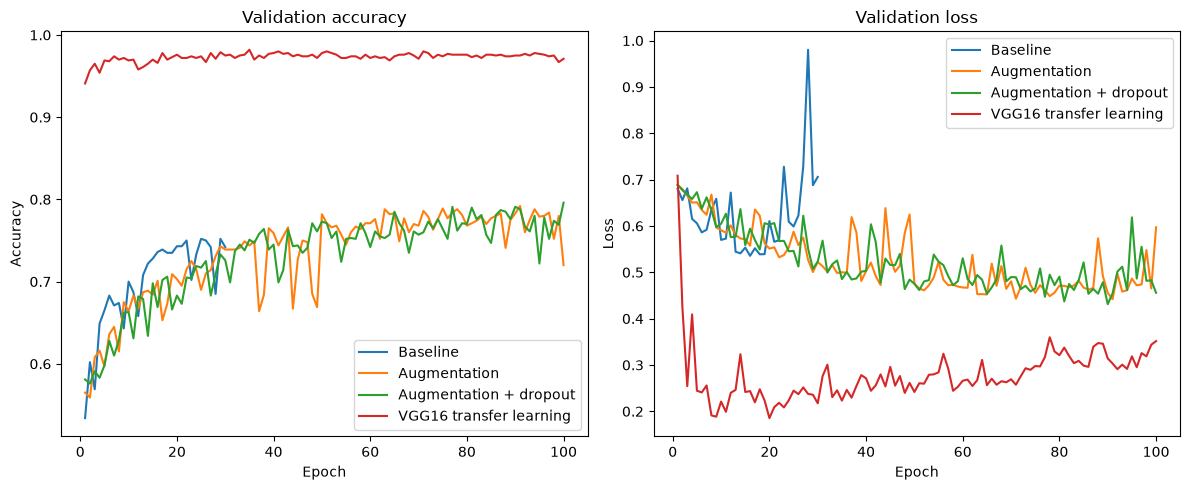

50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.9710 - loss: 0.2040
Test loss: 0.204
Test accuracy: 0.971


In [15]:
import matplotlib.pyplot as plt

runs = [
    (baseline_history, "Baseline"),
    (aug_history, "Augmentation"),
    (dropout_history, "Augmentation + dropout"),
    (transfer_history, "VGG16 transfer learning"),
]

fig, (ax_acc, ax_loss) = plt.subplots(1, 2, figsize=(12, 5))

for run, label in runs:
    epochs = range(1, len(run.history["val_accuracy"]) + 1)
    ax_acc.plot(epochs, run.history["val_accuracy"], label=label)
    ax_loss.plot(epochs, run.history["val_loss"], label=label)

ax_acc.set(title="Validation accuracy", xlabel="Epoch", ylabel="Accuracy")
ax_loss.set(title="Validation loss", xlabel="Epoch", ylabel="Loss")
ax_acc.legend()
ax_loss.legend()

plt.tight_layout()
plt.show()

test_loss, test_accuracy = model_transfer.evaluate(test_dataset)
print(f"Test loss: {test_loss:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")

# Summary

This is the end of the main part of the task, that you need to finish to pass this labs. You should now have results for:


*   Results of training a basic model without any regularisation techniques
*   Results from adding augmentation
*   Results from adding dropout (or both)
*   Results from using a pre-trained model (with or without augmentation and dropout)

As you see, you might have a different combinations of these tools. Please include in your final notebook at least three plots or (if you were saving history of previous trainings) compare them on one plot.

**Please send the completed notebook to the Moodle platform.**

You only send this task, I do not need the MNIST one.

If you finish before the end of the classess, there are two bonus tasks below.



# Bonus Task 1 - Fine-tuning

Another widely used technique for model reuse, complementary to feature extraction, is fine-tuning. Fine-tuning consists of unfreezing a few of the top layers of a frozen model base used for feature extraction, and jointly training both the newly added part of the model.

It is only possible to fine-tune the top layers of the convolutional base once the classifier on top has already been trained. If the classified wasn't already trained, then the error signal propagating through the network during training would be too large, and the representations previously learned by the layers being fine-tuned would be destroyed. Thus the steps for fine-tuning a network are as follow:
1) Add your custom network on top of an already trained base network.
2) Freeze the base network.
3) Train the part you added.
4) Unfreeze some layers in the base network.
5) Train both these layers and the part you added once again.

We have already completed the first 3 steps when doing feature extraction. Let's proceed with the 4th step: we will unfreeze our conv_base, and then freeze individual layers inside of it.

We will fine-tune the last 3 convolutional layers, which means that all layers up until block4_pool should be frozen, and the layers block5_conv1, block5_conv2 and block5_conv3 should be trainable.

Let's set this up, starting from where we left off in the previous example:

In [16]:
conv_base.trainable = True

set_trainable = False
for layer in conv_base.layers:
    if layer.name == 'block5_conv1':
        set_trainable = True
    if set_trainable:
        layer.trainable = True
    else:
        layer.trainable = False

Now we can start fine-tuning our network. We will do this with the RMSprop optimizer, using a very low learning rate. The reason for using a low learning rate is that we want to limit the magnitude of the modifications we make to the representations of the 3 layers that we are fine-tuning. Updates that are too large may harm these representations.

In [17]:
from tensorflow import keras
import matplotlib.pyplot as plt

conv_base.trainable = True

# Freeze through block4_pool; unfreeze block5_conv1, block5_conv2, block5_conv3.
unfreeze = False
for layer in conv_base.layers:
    if layer.name == "block5_conv1":
        unfreeze = True
    layer.trainable = unfreeze

model_transfer.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

fine_tune_history = model_transfer.fit(
    train_dataset,
    epochs=100,
    validation_data=val_dataset,
    callbacks=[early_stop]
)


Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 10s 89ms/step - accuracy: 0.9655 - loss: 0.1294 - val_accuracy: 0.9730 - val_loss: 0.2080
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 85ms/step - accuracy: 0.9680 - loss: 0.1020 - val_accuracy: 0.9720 - val_loss: 0.1920
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 85ms/step - accuracy: 0.9695 - loss: 0.0987 - val_accuracy: 0.9740 - val_loss: 0.2102
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 85ms/step - accuracy: 0.9700 - loss: 0.1018 - val_accuracy: 0.9690 - val_loss: 0.1982
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 83ms/step - accuracy: 0.9750 - loss: 0.0790 - val_accuracy: 0.9720 - val_loss: 0.2132
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 88ms/step - accuracy: 0.9760 - loss: 0.0807 - val_accuracy: 0.9730 - val_loss: 0.2263
Epoch 7/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 83ms/step - accuracy: 0.9785 - loss: 0.0827 - val_accuracy: 0.9710 - val_loss: 0.2359
Epoch 8/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 85ms/step - accuracy: 0.9770 - loss: 0.0765 -

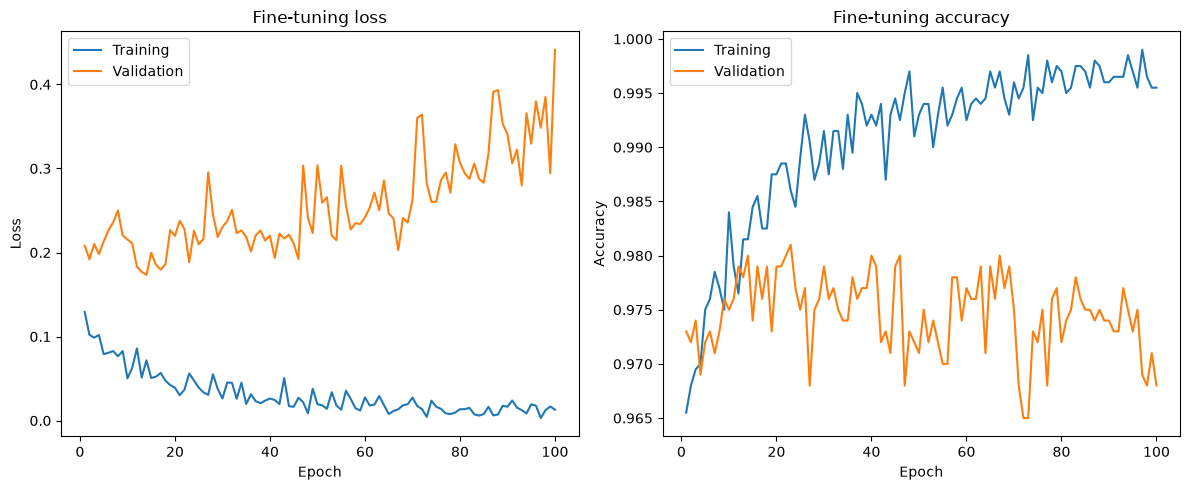

50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.9730 - loss: 0.1902
Test loss: 0.190
Test accuracy: 0.973


In [18]:
epochs = range(1, len(fine_tune_history.history["loss"]) + 1)

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 5))

ax_loss.plot(epochs, fine_tune_history.history["loss"], label="Training")
ax_loss.plot(epochs, fine_tune_history.history["val_loss"], label="Validation")
ax_loss.set(title="Fine-tuning loss", xlabel="Epoch", ylabel="Loss")
ax_loss.legend()

ax_acc.plot(epochs, fine_tune_history.history["accuracy"], label="Training")
ax_acc.plot(epochs, fine_tune_history.history["val_accuracy"], label="Validation")
ax_acc.set(title="Fine-tuning accuracy", xlabel="Epoch", ylabel="Accuracy")
ax_acc.legend()

plt.tight_layout()
plt.show()

test_loss, test_accuracy = model_transfer.evaluate(test_dataset)
print(f"Test loss: {test_loss:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")

# Bonus Task 2 - separate feature extraction

You may have noticed, that training the model with a pre-trained feature extraction takes a lot of time. Even though most layers are frozen, data still have to pass though them in each epoch.

In order to save this time, we may split the process into two parts:



1.   Pass all images throgh the feature extractor only once and save the results into another variable (or even save it into a file for later).
2.   Train the classifier with those feature vectors as an input.

This method can save you time and allow many experiments with combinations of different extractors and classifiers. However there is one major drawback - you cannot use data augmentation with this method. If we augment and generate new images in each epoch, they all have to pass through feature extraction every time.



In [19]:
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers

# Freeze the base while extracting features.
conv_base.trainable = False

def extract_features(dataset):
    feature_batches = []
    label_batches = []

    for images, labels in dataset:
        images = keras.applications.vgg16.preprocess_input(images)
        features = conv_base(images, training=False)

        feature_batches.append(features.numpy())
        label_batches.append(labels.numpy())

    return (
        np.concatenate(feature_batches, axis=0),
        np.concatenate(label_batches, axis=0),
    )

features_train, labels_train = extract_features(train_dataset)
features_val, labels_val = extract_features(val_dataset)

model_classifier = keras.Sequential([
    layers.Input(shape=(4, 4, 512)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

model_classifier.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

feature_history = model_classifier.fit(
    features_train,
    labels_train,
    epochs=100,
    validation_data=(features_val, labels_val),
    callbacks=[early_stop]
)

Epoch 1/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9090 - loss: 1.6654 - val_accuracy: 0.9530 - val_loss: 0.3920
Epoch 2/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9845 - loss: 0.1096 - val_accuracy: 0.9220 - val_loss: 1.0722
Epoch 3/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9940 - loss: 0.0281 - val_accuracy: 0.9600 - val_loss: 0.4783
Epoch 4/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 3.7246e-04 - val_accuracy: 0.9620 - val_loss: 0.3902
Epoch 5/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 2.9777e-04 - val_accuracy: 0.9500 - val_loss: 0.6302
Epoch 6/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9985 - loss: 0.0073 - val_accuracy: 0.9560 - val_loss: 0.4911
Epoch 7/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9990 - loss: 0.0012 - val_accuracy: 0.9610 - val_loss: 0.3796
Epoch 8/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9965 - loss: 0.0179 - val_accuracy: 0

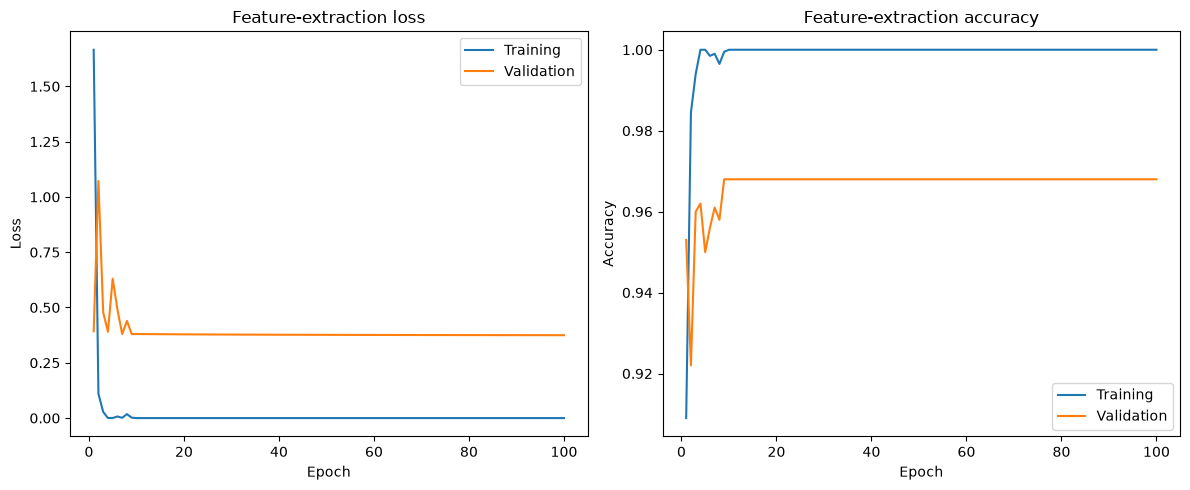

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9660 - loss: 0.3898
Test loss: 0.390
Test accuracy: 0.966


In [20]:
epochs = range(1, len(feature_history.history["loss"]) + 1)

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 5))

ax_loss.plot(epochs, feature_history.history["loss"], label="Training")
ax_loss.plot(epochs, feature_history.history["val_loss"], label="Validation")
ax_loss.set(title="Feature-extraction loss", xlabel="Epoch", ylabel="Loss")
ax_loss.legend()

ax_acc.plot(epochs, feature_history.history["accuracy"], label="Training")
ax_acc.plot(epochs, feature_history.history["val_accuracy"], label="Validation")
ax_acc.set(title="Feature-extraction accuracy", xlabel="Epoch", ylabel="Accuracy")
ax_acc.legend()

plt.tight_layout()
plt.show()

features_test, labels_test = extract_features(test_dataset)
test_loss, test_accuracy = model_classifier.evaluate(features_test, labels_test)
print(f"Test loss: {test_loss:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")